In [1]:
import numpy as np
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats 
from scipy.stats import chi2_contingency, norm
from statsmodels.stats.multitest import multipletests
from skbio.diversity import alpha
import os

# Sampling Summaries

In [2]:
samples = pd.read_excel('Tables/Supplemental Table 1.xlsx')
moss_samples = samples[samples['Substrate']=='moss']['UniqueID'].unique()
lichen_samples = samples[samples['Substrate']=='lichen']['UniqueID'].unique()
print('moss', len(moss_samples))
print('lichen', len(lichen_samples))
samples.head(3)

moss 207
lichen 53


,UniqueID,Latitude,Longitude,Substrate,Location
0,20200511-s01,42.53520,-76.31430,moss,OD von Engeln Nature Preserve
1,20200524-s01,42.48337,-76.38440,moss,Etna Nature Preserve
2,20200524-s02,42.45484,-76.45435,lichen,Fall Creek Valley


In [3]:
mosslichen = dict(zip(samples['UniqueID'], samples['Substrate']))
locations = dict(zip(samples['UniqueID'], samples['Location']))

In [4]:
tardigrades = pd.read_excel('Tables/Supplemental Table 2.xlsx')
tardigrades.head(3)

,Sample ID,TardigradeID (NN),UniqID
0,20200511-s01,t01,20200511-s01-t01
1,20200524-s01,t02,20200524-s01-t02
2,20200524-s01,t03,20200524-s01-t03


# Table 1 and Supplemental Figure 1


all samples
Number of samples :  264
Number of samples with tardigrades :  199
Number of samples without tardigrades :  65
Percentage of samples with tardigrades :  75.0
Mean number tardigrades per sample :  2.88

moss samples
Number of samples :  207
Number of samples with tardigrades :  153
Number of samples without tardigrades :  54
Percentage of samples with tardigrades :  74.0
Mean number tardigrades per sample :  2.99

lichen samples
Number of samples :  53
Number of samples with tardigrades :  44
Number of samples without tardigrades :  9
Percentage of samples with tardigrades :  83.0
Mean number tardigrades per sample :  2.51

Number of samples with >= 10 : 34 


Not moss or lichen: 
<ArrowStringArray>
['pond', 'fungus', 'fungus&lichen', 'moss&lichen']
Length: 4, dtype: str


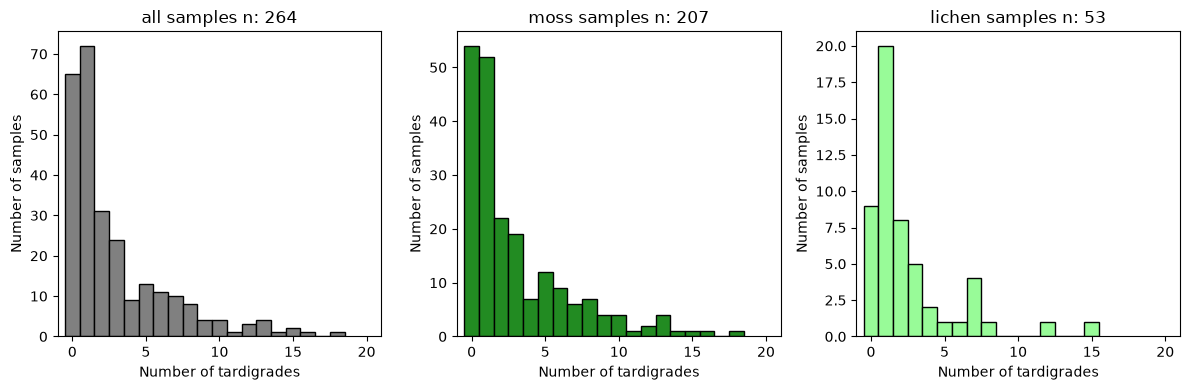

In [5]:
year_threshold = 2020 # when to start keeping track

sample_ids = sorted(samples['UniqueID'].unique()) # all samples

id_types = ['all samples', 'moss samples', 'lichen samples'] 
colors = ['gray', 'forestgreen', 'palegreen']
id_groups = [sample_ids, moss_samples, lichen_samples]
sampletype_data = {}

sampletype_data['Data'] = ['Number of samples', 
                           'Number of samples with tardigrades', 
                           'Number of samples without tardigrades',
                           'Percentage of samples with tardigrades', 
                           'Mean number tardigrades per sample']

f,axes = plt.subplots(1,3,figsize=(12,4))

sample_tardigrades = {}

count_threshold = 10
above_threshold = 0

for i, ids in enumerate(id_groups):
     # dictionary of sampleID -> [list of tardigrades]
    numbers_in_samples = []
    
    for sample_id in ids:
        year = int(sample_id[:4])
        if year >= year_threshold:
            sample_df = tardigrades[tardigrades['Sample ID']==sample_id]
            tardigrades_in_sample = sample_df['UniqID'].values
            if len(tardigrades_in_sample) > 0:
                sample_tardigrades[sample_id] = tardigrades_in_sample
            else:
                sample_tardigrades[sample_id] = []
            numbers_in_samples.append(len(tardigrades_in_sample))
            if len(tardigrades_in_sample) >= count_threshold:
                above_threshold += 1

    numbers_in_samples = np.array(numbers_in_samples)
    number_of_samples = len(numbers_in_samples)
    num_with_tardigrades = len(np.where(numbers_in_samples>0)[0])
    percent_with_tardigrades = np.round(num_with_tardigrades/number_of_samples, 2) * 100
    avg_tardigrades_per_sample = np.round(np.sum(numbers_in_samples) / number_of_samples,2)

    data_this_sample = [int(number_of_samples), int(num_with_tardigrades), 
                        int(len(numbers_in_samples) - num_with_tardigrades), 
                        percent_with_tardigrades,
                        avg_tardigrades_per_sample]

    print()
    print(id_types[i])

    for j, lab in enumerate(sampletype_data['Data']):
        print(lab, ': ', data_this_sample[j])

    sampletype_data[id_types[i]] = np.array(data_this_sample)
    
    min_val = min(numbers_in_samples)
    max_val = max(numbers_in_samples)
    bins = np.arange(min_val, max_val + 2) - 0.5
    
    # Plot histogram
    axes[i].hist(numbers_in_samples, bins=bins, edgecolor='black', align='mid', facecolor=colors[i])
    
    # Force x-axis ticks to show every integer
    # axes[i].set_xticks(range(min_val, max_val + 1))
    axes[i].set_title(id_types[i] + ' n: ' + str(len(numbers_in_samples)))
    axes[i].set_xlabel('Number of tardigrades')
    axes[i].set_ylabel('Number of samples')
    axes[i].set_xlim([-1, 21])

print("\nNumber of samples with >=", count_threshold, ":", above_threshold, "\n")

not_moss_lichen = samples[~samples['Substrate'].isin(['moss','lichen'])]['Substrate'].values
print('\nNot moss or lichen: ')
print(not_moss_lichen)

plt.tight_layout()
# plt.savefig("figs1_sampling.svg", format="svg", bbox_inches="tight")
plt.show()



In [6]:
mosslichen_df = pd.DataFrame(sampletype_data)
# mosslichen_df.to_excel(os.path.join('Table1.xlsx'), index=False)
mosslichen_df.head(5)

,Data,all samples,moss samples,lichen samples
0,Number of samples,264.00,207.00,53.00
1,Number of samples with tardigrades,199.00,153.00,44.00
2,Number of samples without tardigrades,65.00,54.00,9.00
3,Percentage of samples with tardigrades,75.00,74.00,83.00
4,Mean number tardigrades per sample,2.88,2.99,2.51


In [7]:
# chi-squared test
moss_with_tardigrades = sampletype_data['moss samples'][1]
moss_without_tardigrades = sampletype_data['moss samples'][2]

lichen_with_tardigrades = sampletype_data['lichen samples'][1]
lichen_without_tardigrades = sampletype_data['lichen samples'][2]

# contingency table using sample counts
observed = np.array([[moss_with_tardigrades, moss_without_tardigrades],
                     [lichen_with_tardigrades, lichen_without_tardigrades]])

# Chi-Square test of independence
# correction=False ensures standard Pearson calculation without Yates' adjustment
chi2_stat, p_val, dof, expected = stats.chi2_contingency(observed) #, correction=False)

print(f"Chi-Square Statistic: {chi2_stat:.3f}")
print(f"p-value:              {p_val:.3f}")
print(f"Degrees of Freedom:   {dof}")
print()
print("Observed Counts Matrix:")
print(observed)
print("\nExpected Counts Matrix:")
print(expected)

Chi-Square Statistic: 1.442
p-value:              0.230
Degrees of Freedom:   1

Observed Counts Matrix:
[[153.  54.]
 [ 44.   9.]]

Expected Counts Matrix:
[[156.84230769  50.15769231]
 [ 40.15769231  12.84230769]]


In [8]:
# fishers exact test
odds_ratio, p_value = stats.fisher_exact(observed)
print(f"Odds ratio: {odds_ratio:.3f}")
print(f"P-value: {p_value:.3f}")

Odds ratio: 0.580
P-value: 0.209


# Table4: OTUs and sampling
Build dictionary:  
otu --> list of environmental sample IDs 

In [10]:
otu_df = pd.read_excel('Tables/Table 3.xlsx')
otu_order = otu_df['OTU'].values
otu_df.head(3)

,OTU,N,18S accn,18S V4 Top Taxon (accession),18S V4 %ID (alignment length),28S accn,28S Top Taxon (accession),28S %ID (alignment length),COI accn,COI Top Taxon (accession),COI %ID (alignment length)
0,Pseudechiniscus sp. a,17,QB333199,Pseudechiniscus facettalis (HM193382),98.6 (490),QB331945,Pseudechiniscus sp. (PZ748265),100 (433),QB334765,Pseudechiniscus aff. suillus (MK804904),99.2 (607)
1,Viridiscus sp. a,4,QB333200,Echiniscus sp. (EU266975),99.4 (490),QB331946,Viridiscus viridissimus (OK094224),99.9 (736),QB334766,Viridiscus viridissimus (MZ852062),99.7 (611)
2,Viridiscus sp. a3,2,QB333201,Echiniscus sp. (EU266975),98.8 (490),NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
otu_revised_df = pd.read_excel('otu_revision.xlsx')
otu_submitted_to_revised = dict(zip(otu_revised_df['OTU-submitted'], otu_revised_df['OTU-revised']))
otu_revised_df.head(3)

,OTU-submitted,OTU-revised
0,Pseudechiniscus_a,Pseudechiniscus sp. a
1,Echiniscus_a,Viridiscus sp. a
2,Echiniscus_a3,Viridiscus sp. a3


In [12]:
sequence_df = pd.read_excel('Tables/Supplemental Table 3.xlsx')
sequence_df.head(3)

,Index,OTU,SeqID,Notes,Trimmed F566 Sequence
0,1,Adropion sp. a,consensus,Adropion scoticum|MG833237.1|612/612(100%); Ad...,GGTAATTCCAGCTCCAATAGCGTATATTAAAGTTGCTGCGGTTAAA...
1,2,Adropion sp. a,20260704-s10-t03,matches consensus (F and R),CTCGTAGTTGGATCTGGGTAGTCGATGGACGGTGCGGCGTAAGCCG...
2,3,Adropion sp. a,20260516-s05-t09,matches consensus (F and R),CTGCGGTTAAAGCTCGTAGTTGGATCTGGGTAGTCGATGAGCGGTG...


In [13]:
samples_in_otu = {}
for otu in otu_order:
    samples_in_otu[otu] = []
    otu_slice = sequence_df[sequence_df['OTU']==otu]
    tardigrades_in_otu = otu_slice[otu_slice['SeqID']!='consensus']['SeqID'].values
    for tardigrade in tardigrades_in_otu:
        sampleid = tardigrade[:-4]
        if sampleid not in samples_in_otu[otu]:
            samples_in_otu[otu].append(sampleid)
for otu in otu_order:
    print(otu, len(samples_in_otu[otu]))

Pseudechiniscus sp. a 8
Viridiscus sp. a 3
Viridiscus sp. a3 2
Echiniscus sp. b 6
Milnesium sp. a 20
Ramazzottius sp. a 4
Ramazzottius sp. b 6
Ramazzottius sp. b1 25
Ursulinius sp. a 1
Isohypsibius sp. a 2
Isohypsibius sp. a2 3
Isohypsibiidae sp. a11 4
Adropion sp. a 4
Diphascon sp. a 8
Hypsibius sp. a 1
Hypsibius sp. b 3
Hypsibius sp. c 2
Hypsibius sp. d 4
Mesobiotus sp. a 4
Mesobiotus sp. a1 3
Minibiotus sp. a 42
Paramacrobiotus sp. a 15
Paramacrobiotus sp. b 7
Macrobiotus sp. a 19
Macrobiotus sp. b 1
Macrobiotus sp. c 5
Macrobiotus sp. d 4
Macrobiotus sp. e 5
Macrobiotus sp. f 21
Macrobiotus sp. f1 8
Macrobiotus sp. g 1


In [14]:
# which samples are lichen and which are moss?
# have moss_samples and lichen_samples from above
num_moss = len(moss_samples)
num_lichen = len(lichen_samples)
print('moss', num_moss)
print('lichen', num_lichen)

moss 207
lichen 53


In [15]:
# make a dataframe
otu_sample_df = pd.DataFrame({'OTU':otu_order})

# for each OTU get number of moss samples, and number of lichen samples

num_samples_for_otu = np.zeros(len(otu_order))
num_locations_for_otu = np.zeros(len(otu_order))
moss_with_otu = np.zeros(len(otu_order))
lichen_with_otu = np.zeros(len(otu_order))
percent_of_moss_samples = np.zeros(len(otu_order))
percent_of_lichen_samples = np.zeros(len(otu_order))

for i, otu in enumerate(otu_order):

    samples_for_this_otu = samples_in_otu[otu]
    num_samples_for_otu[i] = len(samples_for_this_otu)

    locations_for_otu = np.unique([locations[x] for x in samples_for_this_otu])
    num_locations_for_otu[i] = len(locations_for_otu)
    
    moss_with_otu[i] = len([x for x in moss_samples if x in samples_for_this_otu])
    lichen_with_otu[i] = len([x for x in lichen_samples if x in samples_for_this_otu])

    percent_of_moss_samples[i] = np.round(moss_with_otu[i] / num_moss * 100, 1)
    percent_of_lichen_samples[i] = np.round(lichen_with_otu[i] / num_lichen * 100, 1)

otu_sample_df['# samples'] = [int(x) for x in num_samples_for_otu]
otu_sample_df['# locations'] = [int(x) for x in num_locations_for_otu]
otu_sample_df['moss samples'] = [int(x) for x in moss_with_otu]
otu_sample_df['% of moss samples'] = percent_of_moss_samples
otu_sample_df['lichen samples'] = [int(x) for x in lichen_with_otu]
otu_sample_df['% of lichen samples'] = percent_of_lichen_samples

otu_sample_df.head(5)

,OTU,# samples,# locations,moss samples,% of moss samples,lichen samples,% of lichen samples
0,Pseudechiniscus sp. a,8,6,6,2.9,2,3.8
1,Viridiscus sp. a,3,1,3,1.4,0,0.0
2,Viridiscus sp. a3,2,1,2,1.0,0,0.0
3,Echiniscus sp. b,6,4,5,2.4,1,1.9
4,Milnesium sp. a,20,11,14,6.8,6,11.3


In [14]:
# otu_sample_df.to_excel('Table4.xlsx', index=False)

# Community Composition, moss vs. lichen
Group OTUs by genus.  
Omit genera with low (<5) counts.  
Chi-Squared

In [16]:
df_for_stats = otu_sample_df.copy()
# df_for_stats = pd.read_excel('Tables/Table 4.xlsx')
genera = np.unique([x.split('_')[0] for x in df_for_stats['OTU'].values])
min_count = 5
large_genera = []
moss_counts = []
lichen_counts = []
for genus in genera:
    genera_df = df_for_stats[df_for_stats['OTU'].str.startswith(genus)]
    total_moss = np.sum(genera_df['moss samples'].values)
    total_lichen = np.sum(genera_df['lichen samples'].values)
    if total_moss >= min_count and total_lichen >= min_count:
        large_genera.append(genus)
        moss_counts.append(total_moss)
        lichen_counts.append(total_lichen)

print(large_genera)
chi2, p_value, dof, expected = chi2_contingency([moss_counts, lichen_counts])
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

[np.str_('Macrobiotus sp. a'), np.str_('Milnesium sp. a'), np.str_('Minibiotus sp. a'), np.str_('Ramazzottius sp. b'), np.str_('Ramazzottius sp. b1')]
Chi-Square Statistic: 7.0398
p-value: 0.1338
Degrees of Freedom: 4


In [16]:
# # from scipy.stats import fisher_exact
# from statsmodels.stats.multitest import multipletests

# sampling saturation
* Sampling OTU asymptote.

In [17]:
# get list of IDs for sequenced tardigrades
sequenced_tardigrades = []
for otu in otu_order:
    otu_slice = sequence_df[sequence_df['OTU']==otu]
    tardigrades_in_otu = otu_slice[otu_slice['SeqID']!='consensus']['SeqID'].values
    sequenced_tardigrades.extend(tardigrades_in_otu)
sequenced_tardigrade_df = tardigrades[tardigrades['UniqID'].isin(sequenced_tardigrades)].copy()
print(len(sequenced_tardigrade_df))
sequenced_tardigrade_df.head(3)

427


,Sample ID,TardigradeID (NN),UniqID
0,20200511-s01,t01,20200511-s01-t01
1,20200524-s01,t02,20200524-s01-t02
2,20200524-s01,t03,20200524-s01-t03


In [18]:
# sort tardigrades by SampleID = sample date
tmp = sequenced_tardigrade_df.sort_values(by='Sample ID')
sequenced_tardigrade_df = tmp
sequenced_tardigrade_df.head(3)

,Sample ID,TardigradeID (NN),UniqID
0,20200511-s01,t01,20200511-s01-t01
1,20200524-s01,t02,20200524-s01-t02
2,20200524-s01,t03,20200524-s01-t03


In [19]:
# Add OTUs
id_to_otu = dict(zip(sequence_df['SeqID'],sequence_df['OTU']))
sequenced_tardigrade_df['OTU'] = [id_to_otu[x] for x in sequenced_tardigrade_df['UniqID'].values]
sequenced_tardigrade_df.head(5)

,Sample ID,TardigradeID (NN),UniqID,OTU
0,20200511-s01,t01,20200511-s01-t01,Macrobiotus sp. f
1,20200524-s01,t02,20200524-s01-t02,Isohypsibius sp. a2
2,20200524-s01,t03,20200524-s01-t03,Minibiotus sp. a
3,20200524-s02,t05,20200524-s02-t05,Milnesium sp. a
4,20200524-s03,t02,20200524-s03-t02,Minibiotus sp. a


### Remove samples from outside ithaca area

In [21]:
# remove samples from Georgia, Virginia, and 2025 (resampling of Ithaca College)
# filtered_2025 = sequenced_tardigrade_df[~sequenced_tardigrade_df['Sample ID'].str.startswith('2025', na=False)]
# print(len(sequenced_tardigrade_df), 'Sequenced')
# print(len(filtered_2025), 'with 2025 removed')
print('Starting with ...')
print(len(sequenced_tardigrade_df), 'tardigrades')
print(len(sequenced_tardigrade_df['Sample ID'].unique()), 'samples')

print()
filtered_tifton = sequenced_tardigrade_df[~sequenced_tardigrade_df['Sample ID'].str.startswith('20260527', na=False)]
print(len(filtered_tifton), 'tardigrades with Georgia removed')
filtered_virginia = filtered_tifton[~filtered_tifton['Sample ID'].str.startswith('20260528', na=False)]
print(len(filtered_virginia), 'tardigrades with Virginia removed')
filtered_pr = filtered_virginia[~filtered_virginia['Sample ID'].str.startswith('20260318', na=False)]
print(len(filtered_pr), 'tardigrades with Puerto Rico removed')
filtered_df = filtered_pr[~filtered_pr['Sample ID'].str.startswith('20260524-s01', na=False)] # cranberry  lake
print(len(filtered_df), 'tardigrades with Cranberry Lake removed')
print()
print(len(filtered_df['Sample ID'].unique()), 'samples')

Starting with ...
427 tardigrades
156 samples

417 tardigrades with Georgia removed
402 tardigrades with Virginia removed
401 tardigrades with Puerto Rico removed
394 tardigrades with Cranberry Lake removed

148 samples


In [22]:
df_to_count = filtered_df # filtered_pr or sequenced

sample_ids = df_to_count['Sample ID'].values
otus = df_to_count['OTU'].values
samples_for_counting = []
sample_count = 0
counted_otus = []
otu_count = 0
current_sample = ''
sample_axis = []
otu_axis = []

print('sample          OTU          \t#samps\t#otus')
for i, sample_id in enumerate(sample_ids):
    if sample_id == current_sample:
        if otus[i] not in counted_otus and 'unknown' not in otus[i]:
            otu_count += 1
            counted_otus.append(otus[i])
            print('\t'.join([sample_id, otus[i], str(sample_count), str(otu_count)]))
    else: # a new sample
        current_sample = sample_id
        sample_count += 1
        if otus[i] not in counted_otus and 'unknown' not in otus[i]:
            otu_count += 1
            counted_otus.append(otus[i])
            print('\t'.join([sample_id, otus[i], str(sample_count), str(otu_count)]))
    sample_axis.append(sample_count)
    otu_axis.append(otu_count)

# species are printed out in the order found

sample          OTU          	#samps	#otus
20200511-s01	Macrobiotus sp. f	1	1
20200524-s01	Isohypsibius sp. a2	2	2
20200524-s01	Minibiotus sp. a	2	3
20200524-s02	Milnesium sp. a	3	4
20200617-s06	Macrobiotus sp. f1	6	5
20200629-s03	Hypsibius sp. d	8	6
20200629-s04	Diphascon sp. a	9	7
20200629-s05	Adropion sp. a	10	8
20200703-s02	Mesobiotus sp. a	13	9
20210901-s01	Ramazzottius sp. a	14	10
20210901-s01	Viridiscus sp. a3	14	11
20210901-s03	Ramazzottius sp. b1	16	12
20240926-s01	Paramacrobiotus sp. a	18	13
20240926-s24	Macrobiotus sp. a	23	14
20241002-s01	Paramacrobiotus sp. b	24	15
20241002-s04	Hypsibius sp. b	27	16
20241002-s10	Macrobiotus sp. b	30	17
20241009-s05	Viridiscus sp. a	36	18
20241009-s08	Macrobiotus sp. e	37	19
20241021-s02	Ramazzottius sp. b	43	20
20260516-s01	Pseudechiniscus sp. a	60	21
20260516-s05	Isohypsibius sp. a	61	22
20260516-s07	Echiniscus sp. b	63	23
20260517-s01	Hypsibius sp. c	64	24
20260521-s02	Mesobiotus sp. a1	65	25
20260531-s05	Hypsibius sp. a	71	26
20260604-s

In [23]:
print(sample_axis[:10]) # looks OK
print(otu_axis[:10]) # looks OK

[1, 2, 2, 3, 4, 5, 6, 7, 8, 8]
[1, 2, 3, 4, 4, 4, 5, 5, 6, 6]


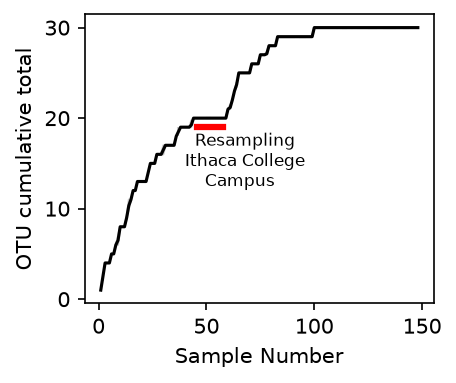

In [24]:
f, ax = plt.subplots(1,1,figsize=(3,2.5), dpi=150)
sns.lineplot(x=sample_axis, y=otu_axis, color='k', ax=ax)
# plt.plot([56,56], [0,36], '--r')
plt.text(40, 12.5, '  Resampling\nIthaca College\n    Campus', fontsize=8) 
plt.plot([45.5, 57.5], [19, 19], '-r', linewidth=3)
# plt.text(100, 25, '   Outside of\nIthaca College')
plt.xlabel('Sample Number', fontsize=10)
plt.ylabel('OTU cumulative total', fontsize=10)
ax.tick_params(axis="both", labelsize=10)
# plt.savefig('figx_species_accumulation.png', bbox_inches='tight', transparent=True)
plt.show()

In [25]:
print(len(df_to_count['Sample ID'].unique()))
print(len(df_to_count['OTU'].unique()))

148
30


In [26]:
# make a version of otus and sample types where non-ithaca samples are omitted
good_samples = filtered_df['Sample ID'].values
print(len(good_samples))

394


In [32]:
# make a dataframe
otu_goodsample_df = pd.DataFrame({'OTU':otu_order})

# for each OTU get number of moss samples, and number of lichen samples

num_samples_for_otu = np.zeros(len(otu_order))
num_locations_for_otu = np.zeros(len(otu_order))
moss_with_otu = np.zeros(len(otu_order))
lichen_with_otu = np.zeros(len(otu_order))
percent_of_moss_samples = np.zeros(len(otu_order))
percent_of_lichen_samples = np.zeros(len(otu_order))

for i, otu in enumerate(otu_order):

    samples_for_this_otu = samples_in_otu[otu]
    samples_for_this_otu = [x for x in samples_for_this_otu if x in good_samples]
    num_samples_for_otu[i] = len(samples_for_this_otu)

    locations_for_otu = np.unique([locations[x] for x in samples_for_this_otu])
    num_locations_for_otu[i] = len(locations_for_otu)
    
    moss_with_otu[i] = len([x for x in moss_samples if x in samples_for_this_otu])
    lichen_with_otu[i] = len([x for x in lichen_samples if x in samples_for_this_otu])

    percent_of_moss_samples[i] = np.round(moss_with_otu[i] / num_moss * 100, 1)
    percent_of_lichen_samples[i] = np.round(lichen_with_otu[i] / num_lichen * 100, 1)

otu_goodsample_df['# samples'] = [int(x) for x in num_samples_for_otu]
otu_goodsample_df['# locations'] = [int(x) for x in num_locations_for_otu]
otu_goodsample_df['moss samples'] = [int(x) for x in moss_with_otu]
otu_goodsample_df['% of moss samples'] = percent_of_moss_samples
otu_goodsample_df['lichen samples'] = [int(x) for x in lichen_with_otu]
otu_goodsample_df['% of lichen samples'] = percent_of_lichen_samples

print(len(otu_goodsample_df))
otu_goodsample_df.head(5)

31


,OTU,# samples,# locations,moss samples,% of moss samples,lichen samples,% of lichen samples
0,Pseudechiniscus sp. a,8,6,6,2.9,2,3.8
1,Viridiscus sp. a,3,1,3,1.4,0,0.0
2,Viridiscus sp. a3,2,1,2,1.0,0,0.0
3,Echiniscus sp. b,6,4,5,2.4,1,1.9
4,Milnesium sp. a,19,10,13,6.3,6,11.3


In [33]:
# remove otus with zero records
otu_goodsamples_above_zero_df = otu_goodsample_df[otu_goodsample_df['# samples']>0]
print(len(otu_goodsamples_above_zero_df))
otu_goodsamples_above_zero_df.head(5)

30


,OTU,# samples,# locations,moss samples,% of moss samples,lichen samples,% of lichen samples
0,Pseudechiniscus sp. a,8,6,6,2.9,2,3.8
1,Viridiscus sp. a,3,1,3,1.4,0,0.0
2,Viridiscus sp. a3,2,1,2,1.0,0,0.0
3,Echiniscus sp. b,6,4,5,2.4,1,1.9
4,Milnesium sp. a,19,10,13,6.3,6,11.3


In [34]:
sample_counts = otu_goodsamples_above_zero_df['# samples'].values
chao1_val = alpha.chao1(sample_counts)
ace_val = alpha.ace(sample_counts)
print(f"Chao1: {chao1_val:.2f}")
print(f"ACE: {ace_val:.2f}")

Chao1: 30.60
ACE: 31.03
